# Python Series 03 - A
Maïwenn RODRIGUES

# 1. Create GitHub repository
OK

# 2. Create functions to find and plot remarkable points


In [89]:
index =  [    0,    1,    2,    3,    4,    5,    6,    7,    8,    9   ]
signal =  [   -1,    1,    2,    1,    0,   -1,    1,    2,    1,   -2   ]

import matplotlib.pyplot as plt
import numpy as np

# 2.1 Explaining and improving the code
## Add docstrings and explanatory comments

In [90]:
def find_zero_crossings_no_zeros(signs: np.ndarray):
    """
    On veut trouver les passages à zéro dans un tableau de signes sans zéros

    Inputs/Entrées :
    signs = le tableau de signes contenant seulement les signes du signal (1 pour positif, -1 pour négatif)

    Outputs/Sorties :
    i_cross_pos = indices des passages de négatif à positif
    i_cross_neg = indices des passages de positif à négatif
    """
    diff = np.diff(signs)
    i_cross_pos = np.where(diff > 0)[0] # on cherche les indices où la différence est > 0 (négatif à positif)
    i_cross_neg = np.where(diff < 0)[0] # on cherche les indices où la différence est < 0 (positif à négatif)
    return i_cross_pos, i_cross_neg


def propagate_signs_over_zeros(signs: np.ndarray):
    """
    On veut trouver les passages à zéro dans un tableau de signes avec des zéros. Pour cela, le but est de remplacer chaque 0 par le signe qui le précède.

    Inputs/Entrées :
    signs = le tableau de signes contenant seulement les signes du signal
    
    Outputs/Sorties :
    signs_no_zeros = un nouveau tableau de signe où tous les 0 ont été remplacé par le signe précédent 
    """

    signs_no_zeros = signs.copy()

    mask = signs_no_zeros != 0 # mask permet de créer un tableau True or False et permet de filtrer les données (ici 0 = False)
    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0)  # récupère l'index des données valides (True) et note 0 pour les données non valides (False)
    idx = np.maximum.accumulate(idx)  # lit le tableau de gauche à droite en retenant l'index maximum lu donc quand ça tombe sur un 0, ça le remplace par le bon signe (-1 ou +1)
    signs_no_zeros = signs_no_zeros[idx]  # construit le nouveau tableau qui tient compte des critères ci-dessus (0 remplacé par -1 ou +1)

    if signs_no_zeros[0] == 0:  # si tableau commence par un 0
        i_first_nonzero = np.where(signs != 0)[0]  # on cherche l'index des données valides
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]  # on remplace le 0 du début par le signe valide qui le succède

    return signs_no_zeros


def find_zero_crossings(s: np.ndarray):
    """
    On veut trouver les passages à zéro dans un signal 1D
    
    Inputs/Entrées :
    s = le signal brut issu du tableau
        
    Outputs/Sorties :
    find_zero_crossings_no_zeros soit 
        i_cross_pos = indices des passages de négatif à positif
        i_cross_neg = indices des passages de positif à négatif
    """

    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")  # vérifier que le signal est bien 1D sinon il y a une erreur

    signs = np.sign(s).astype(int)  # on récupère les signes du signal
    i_zeros = np.where(signs == 0)[0]  # on récupère les indices des zéros du signal
    if i_zeros.size > 0:  # s'il y a des 0, on les remplace par le signe précédent
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs # si pas de 0, on garde le tableau de signe tel quel

    return find_zero_crossings_no_zeros(signs_no_zeros)

## Role of the unit tests

Le rôle des tests unitaires est de vérifier si le code fonctionne. On donne à la fonction un signal dont la réponse est connue. Si la fonction trouve la bonne réponse, le test est réussi. Si elle ne trouve pas, une erreur est signalée (grâce à assert).

In [91]:
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function."""
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))

    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))

    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))

    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))

""" Additional test cases  """

s = np.array([1, 1, 1, 1, 1, 1])
# expected    no crossings
i_pos, i_neg = find_zero_crossings(s)
assert np.array_equal(i_pos, np.array([]))
assert np.array_equal(i_neg, np.array([]))

s = np.array([-1, -1, -1, -1, -1, -1])
# expected    no crossings
i_pos, i_neg = find_zero_crossings(s)
assert np.array_equal(i_pos, np.array([]))
assert np.array_equal(i_neg, np.array([]))

s = np.array([0, 0, 0, 0, 0])
# expected    no crossings  
i_pos, i_neg = find_zero_crossings(s)
assert np.array_equal(i_pos, np.array([]))
assert np.array_equal(i_neg, np.array([]))


# Testing the function
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error

All tests passed.


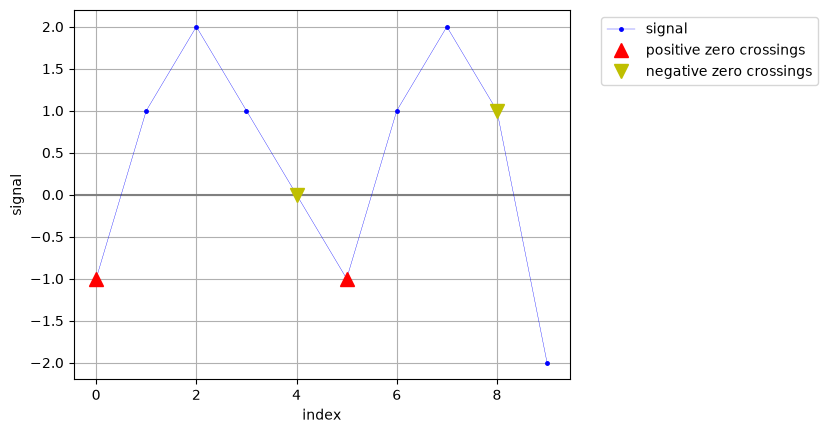

In [92]:
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Plot the signal as function of time/index with grid and zero line"""
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")


def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Plot remarkable points on a signal with format and label"""
    plt.plot(t, s, format, markersize=10, label=label)


def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot positive zero crossings on a signal"""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")


def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot negative zero crossings on a signal"""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")


def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot all zero crossings on a signal"""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Plot signal and zero crossings with legend outside the plot and grid"""
    plt.figure()
    plot_signal(i, s)
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)
    # NOTE: legend outside does not work well with %matplotlib widget
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(np.array(index), np.array(signal))

# 2.3  Create new functions to find the local maxima and minima

In [93]:
# Create new functions to find the local maxima a signal
def find_local_maxima(s: np.ndarray):
    """
    Find local maxima in a 1D signal.

    Inputs:
    s = the input signal

    Outputs:
    i_max = indices of local maxima
    """
    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # un maxima local est un point plus grand que les points qui l'entourent
    i_max = np.where((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:]))[0] + 1
    return i_max

In [94]:
# Create new functions to find the local minima of a signal
def find_local_minima(s: np.ndarray):
    """
    Find local minima in a 1D signal.

    Inputs:
    s = the input signal

    Outputs:
    i_min = indices of local minima 
    """
    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # un minima local est un point plus petit que les points qui l'entourent
    i_min = np.where((s[1:-1] < s[:-2]) & (s[1:-1] < s[2:]))[0] + 1
    return i_min

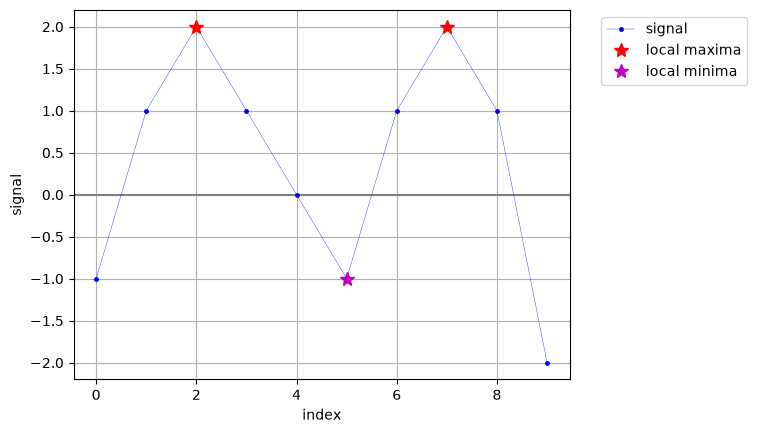

In [95]:
# on s'assure que index et signal sont bien des tableaux 
i_arr = np.array(index)
s_arr = np.array(signal)

# calcul des positions des maxima et minima grâce aux fonctions
i_max = find_local_maxima(s_arr)
i_min = find_local_minima(s_arr)

plt.figure()  # création du graphique
plot_signal(i_arr, s_arr)  # on trace le signal de base

plot_remarkable_points(i_arr[i_max], s_arr[i_max], "*r", "local maxima")  # ajout des maxima avec des étoiles rouges ("*r")
plot_remarkable_points(i_arr[i_min], s_arr[i_min], "*m", "local minima")  # ajout des minima avec des étoiles magenta ("*m")

# affichage de la légende et du quadrillage
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()